In [1]:
import pandas as pd
import polars as pl
import numpy as np
import pyreadstat as prs

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf
import statsmodels.api as sm
import statsmodels
from statsmodels.iolib.summary2 import summary_col

# utils

In [2]:
from statsmodels.graphics.gofplots import ProbPlot
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import maybe_unwrap_results

style_talk = "seaborn-talk"  # refer to plt.style.available


class LinearRegDiagnostic:
    """
    Diagnostic plots to identify potential problems in a linear regression fit.
    Mainly,
        a. non-linearity of data
        b. Correlation of error terms
        c. non-constant variance
        d. outliers
        e. high-leverage points
        f. collinearity

    Authors:
        Prajwal Kafle (p33ajkafle@gmail.com, where 3 = r)
        Does not come with any sort of warranty.
        Please test the code one your end before using.

        Matt Spinelli (m3spinelli@gmail.com, where 3 = r)
        (1) Fixed incorrect annotation of the top most extreme residuals in
            the Residuals vs Fitted and, especially, the Normal Q-Q plots.
        (2) Changed Residuals vs Leverage plot to match closer the y-axis
            range shown in the equivalent plot in the R package ggfortify.
        (3) Added horizontal line at y=0 in Residuals vs Leverage plot to
            match the plots in R package ggfortify and base R.
        (4) Added option for placing a vertical guideline on the Residuals
            vs Leverage plot using the rule of thumb of h = 2p/n to denote
            high leverage (high_leverage_threshold=True).
        (5) Added two more ways to compute the Cook's Distance (D) threshold:
            * 'baseR': D > 1 and D > 0.5 (default)
            * 'convention': D > 4/n
            * 'dof': D > 4 / (n - k - 1)
        (6) Fixed class name to conform to Pascal casing convention
        (7) Fixed Residuals vs Leverage legend to work with loc='best'
    """

    def __init__(
        self,
        results: type[statsmodels.regression.linear_model.RegressionResultsWrapper],
    ) -> None:
        """
        For a linear regression model, generates following diagnostic plots:

        a. residual
        b. qq
        c. scale location and
        d. leverage

        and a table

        e. vif

        Args:
            results (Type[statsmodels.regression.linear_model.RegressionResultsWrapper]):
                must be instance of statsmodels.regression.linear_model object

        Raises:
            TypeError: if instance does not belong to above object

        Example:
        >>> import numpy as np
        >>> import pandas as pd
        >>> import statsmodels.formula.api as smf
        >>> x = np.linspace(-np.pi, np.pi, 100)
        >>> y = 3*x + 8 + np.random.normal(0,1, 100)
        >>> df = pd.DataFrame({'x':x, 'y':y})
        >>> res = smf.ols(formula= "y ~ x", data=df).fit()
        >>> cls = Linear_Reg_Diagnostic(res)
        >>> cls(plot_context="seaborn-v0_8-paper")

        In case you do not need all plots you can also independently make an individual plot/table
        in following ways

        >>> cls = Linear_Reg_Diagnostic(res)
        >>> cls.residual_plot()
        >>> cls.qq_plot()
        >>> cls.scale_location_plot()
        >>> cls.leverage_plot()
        >>> cls.vif_table()
        """

        if (
            isinstance(
                results, statsmodels.regression.linear_model.RegressionResultsWrapper
            )
            is False
        ):
            raise TypeError(
                "result must be instance of statsmodels.regression.linear_model.RegressionResultsWrapper object"
            )

        self.results = maybe_unwrap_results(results)

        self.y_true = self.results.model.endog
        self.y_predict = self.results.fittedvalues
        self.xvar = self.results.model.exog
        self.xvar_names = self.results.model.exog_names

        self.residual = np.array(self.results.resid)
        influence = self.results.get_influence()
        self.residual_norm = influence.resid_studentized_internal
        self.leverage = influence.hat_matrix_diag
        self.cooks_distance = influence.cooks_distance[0]
        self.nparams = len(self.results.params)
        self.nresids = len(self.residual_norm)

    def __call__(self, plot_context="seaborn-v0_8-paper", **kwargs):
        # print(plt.style.available)
        # GH#9157
        if plot_context not in plt.style.available:
            plot_context = "default"
        with plt.style.context(plot_context):
            fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))
            self.residual_plot(ax=ax[0, 0])
            self.qq_plot(ax=ax[0, 1])
            self.scale_location_plot(ax=ax[1, 0])
            self.leverage_plot(
                ax=ax[1, 1],
                high_leverage_threshold=kwargs.get("high_leverage_threshold"),
                cooks_threshold=kwargs.get("cooks_threshold"),
            )
            plt.show()

        return (
            self.vif_table(),
            fig,
            ax,
        )

    def residual_plot(self, ax=None):
        """
        Residual vs Fitted Plot

        Graphical tool to identify non-linearity.
        (Roughly) Horizontal red line is an indicator that the residual has a linear pattern
        """
        if ax is None:
            fig, ax = plt.subplots()

        sns.residplot(
            x=self.y_predict,
            y=self.residual,
            lowess=True,
            scatter_kws={"alpha": 0.5},
            line_kws={"color": "red", "lw": 1, "alpha": 0.8},
            ax=ax,
        )

        # annotations
        residual_abs = np.abs(self.residual)
        abs_resid = np.flip(np.argsort(residual_abs), 0)
        abs_resid_top_3 = abs_resid[:3]
        for i in abs_resid_top_3:
            ax.annotate(i, xy=(self.y_predict[i], self.residual[i]), color="C3")

        ax.set_title("Residuals vs Fitted", fontweight="bold")
        ax.set_xlabel("Fitted values")
        ax.set_ylabel("Residuals")
        return ax

    def qq_plot(self, ax=None):
        """
        Standarized Residual vs Theoretical Quantile plot

        Used to visually check if residuals are normally distributed.
        Points spread along the diagonal line will suggest so.
        """
        if ax is None:
            fig, ax = plt.subplots()

        QQ = ProbPlot(self.residual_norm)
        QQ.qqplot(line="45", alpha=0.5, lw=1, ax=ax)

        # annotations
        abs_norm_resid = np.flip(np.argsort(np.abs(self.residual_norm)), 0)
        abs_norm_resid_top_3 = abs_norm_resid[:3]
        for i, x, y in self.__qq_top_resid(
            QQ.theoretical_quantiles, abs_norm_resid_top_3
        ):
            ax.annotate(i, xy=(x, y), ha="right", color="C3")

        ax.set_title("Normal Q-Q", fontweight="bold")
        ax.set_xlabel("Theoretical Quantiles")
        ax.set_ylabel("Standardized Residuals")
        return ax

    def scale_location_plot(self, ax=None):
        """
        Sqrt(Standarized Residual) vs Fitted values plot

        Used to check homoscedasticity of the residuals.
        Horizontal line will suggest so.
        """
        if ax is None:
            fig, ax = plt.subplots()

        residual_norm_abs_sqrt = np.sqrt(np.abs(self.residual_norm))

        ax.scatter(self.y_predict, residual_norm_abs_sqrt, alpha=0.5)
        sns.regplot(
            x=self.y_predict,
            y=residual_norm_abs_sqrt,
            scatter=False,
            ci=False,
            lowess=True,
            line_kws={"color": "red", "lw": 1, "alpha": 0.8},
            ax=ax,
        )

        # annotations
        abs_sq_norm_resid = np.flip(np.argsort(residual_norm_abs_sqrt), 0)
        abs_sq_norm_resid_top_3 = abs_sq_norm_resid[:3]
        for i in abs_sq_norm_resid_top_3:
            ax.annotate(
                i, xy=(self.y_predict[i], residual_norm_abs_sqrt[i]), color="C3"
            )

        ax.set_title("Scale-Location", fontweight="bold")
        ax.set_xlabel("Fitted values")
        ax.set_ylabel(r"$\sqrt{|\mathrm{Standardized\ Residuals}|}$")
        return ax

    def leverage_plot(
        self, ax=None, high_leverage_threshold=False, cooks_threshold="baseR"
    ):
        """
        Residual vs Leverage plot

        Points falling outside Cook's distance curves are considered observation that can sway the fit
        aka are influential.
        Good to have none outside the curves.
        """
        if ax is None:
            fig, ax = plt.subplots()

        ax.scatter(self.leverage, self.residual_norm, alpha=0.5)

        sns.regplot(
            x=self.leverage,
            y=self.residual_norm,
            scatter=False,
            ci=False,
            lowess=True,
            line_kws={"color": "red", "lw": 1, "alpha": 0.8},
            ax=ax,
        )

        # annotations
        leverage_top_3 = np.flip(np.argsort(self.cooks_distance), 0)[:3]
        for i in leverage_top_3:
            ax.annotate(i, xy=(self.leverage[i], self.residual_norm[i]), color="C3")

        factors = []
        if cooks_threshold == "baseR" or cooks_threshold is None:
            factors = [1, 0.5]
        elif cooks_threshold == "convention":
            factors = [4 / self.nresids]
        elif cooks_threshold == "dof":
            factors = [4 / (self.nresids - self.nparams)]
        else:
            raise ValueError(
                "threshold_method must be one of the following: 'convention', 'dof', or 'baseR' (default)"
            )
        for i, factor in enumerate(factors):
            label = "Cook's distance" if i == 0 else None
            xtemp, ytemp = self.__cooks_dist_line(factor)
            ax.plot(xtemp, ytemp, label=label, lw=1.25, ls="--", color="red")
            ax.plot(xtemp, np.negative(ytemp), lw=1.25, ls="--", color="red")

        if high_leverage_threshold:
            high_leverage = 2 * self.nparams / self.nresids
            if max(self.leverage) > high_leverage:
                ax.axvline(
                    high_leverage, label="High leverage", ls="-.", color="purple", lw=1
                )

        ax.axhline(0, ls="dotted", color="black", lw=1.25)
        ax.set_xlim(0, max(self.leverage) + 0.01)
        ax.set_ylim(min(self.residual_norm) - 0.1, max(self.residual_norm) + 0.1)
        ax.set_title("Residuals vs Leverage", fontweight="bold")
        ax.set_xlabel("Leverage")
        ax.set_ylabel("Standardized Residuals")
        plt.legend(loc="best")
        return ax

    def vif_table(self):
        """
        VIF table

        VIF, the variance inflation factor, is a measure of multicollinearity.
        VIF > 5 for a variable indicates that it is highly collinear with the
        other input variables.
        """
        vif_df = pd.DataFrame()
        vif_df["Features"] = self.xvar_names
        vif_df["VIF Factor"] = [
            variance_inflation_factor(self.xvar, i) for i in range(self.xvar.shape[1])
        ]

        return vif_df.sort_values("VIF Factor").round(2)

    def __cooks_dist_line(self, factor):
        """
        Helper function for plotting Cook's distance curves
        """
        p = self.nparams

        def formula(x):
            return np.sqrt((factor * p * (1 - x)) / x)

        x = np.linspace(0.001, max(self.leverage), 50)
        y = formula(x)
        return x, y

    def __qq_top_resid(self, quantiles, top_residual_indices):
        """
        Helper generator function yielding the index and coordinates
        """
        offset = 0
        quant_index = 0
        previous_is_negative = None
        for resid_index in top_residual_indices:
            y = self.residual_norm[resid_index]
            is_negative = y < 0
            if previous_is_negative is None or previous_is_negative == is_negative:
                offset += 1
            else:
                quant_index -= offset
            x = (
                quantiles[quant_index]
                if is_negative
                else np.flip(quantiles, 0)[quant_index]
            )
            quant_index += 1
            previous_is_negative = is_negative
            yield resid_index, x, y

# data

In [15]:
df = pd.read_parquet('../data/working_set2.parquet')
df = df[~df['diplom'].isin(['NO ANSWER', 'REFUSES TO ANSWER', 'DOES NOT KNOW'])]
df = df[~df['primary_occupation'].isin(['NO ANSWER', 'REFUSES TO ANSWER', 'DOES NOT KNOW'])]
df = df.drop(columns=['ow', 'ow2', 'ow_iea'])
df

,year,family_id,family_member_id,total_income_last30_days,job1_wage,job2_wage,iea_income,pension_benefit,age,gender,...,job_satisfaction,satisfaction_w_pay,satisfaction_w_ow,satisfaction_w_life,is_farmer,nationality,inwgt,hours_worked,family_id_imputed,family_size
0,2015.0,1.0,1.0,40000.0,40000.0,NaN,NaN,NaN,42.0,FEMALE,...,MOSTLY SATISFIED,3.0,NaN,NaN,0,RUSSIAN,0.000000,NaN,1,2
2,2015.0,2.0,3.0,47000.0,47000.0,NaN,NaN,NaN,31.0,FEMALE,...,MOSTLY SATISFIED,2.0,NaN,NaN,0,RUSSIAN,0.000000,189.0,2,1
3,2015.0,3.0,1.0,14514.0,NaN,NaN,NaN,12670.0,71.0,FEMALE,...,NaN,NaN,NaN,NaN,0,RUSSIAN,0.774056,NaN,3,1
4,2015.0,4.0,1.0,13400.0,NaN,NaN,NaN,13400.0,69.0,FEMALE,...,NaN,NaN,NaN,NaN,0,RUSSIAN,0.774056,NaN,4,1
5,2015.0,10.0,1.0,22000.0,NaN,NaN,NaN,12000.0,73.5,FEMALE,...,NaN,NaN,NaN,NaN,0,RUSSIAN,0.000000,NaN,5,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195142,2025.0,90013.0,4.0,80000.0,80000.0,NaN,NaN,NaN,20.5,FEMALE,...,MOSTLY SATISFIED,2.0,2.0,NaN,0,RUSSIAN,0.939756,192.0,68786,5
195144,2025.0,90014.0,1.0,20100.0,NaN,NaN,NaN,20100.0,66.5,FEMALE,...,NaN,NaN,NaN,NaN,0,RUSSIAN,0.742500,NaN,68787,4
195145,2025.0,90014.0,2.0,70000.0,70000.0,NaN,NaN,NaN,38.0,FEMALE,...,ABSOLUTELY SATISTFIED,2.0,2.0,NaN,0,RUSSIAN,1.059966,168.0,68787,4
195146,2025.0,90014.0,4.0,0.0,NaN,NaN,NaN,NaN,17.0,FEMALE,...,NaN,NaN,NaN,NaN,0,RUSSIAN,0.939756,NaN,68787,4


In [16]:
education = df['diplom'].value_counts().reset_index()
# education['education_level'] = [5, 4, 3, 2, 2, 1]
education['education_level'] = [1, 0, 0, 0, 0, 0]
education =  education[['diplom', 'education_level']]
education

,diplom,education_level
0,Secondary School Diploma,1
1,Higher education Diploma and more,0
2,Vocational secondary education Diploma,0
3,Unfinished secondary education [7-8 grades of ...,0
4,Unfinished secondary education [7-8 grades of ...,0
5,0-6 grades of comprehensive school,0


In [17]:
print(pl.from_pandas(education))

shape: (6, 2)
┌─────────────────────────────────┬─────────────────┐
│ diplom                          ┆ education_level │
│ ---                             ┆ ---             │
│ str                             ┆ i64             │
╞═════════════════════════════════╪═════════════════╡
│ Secondary School Diploma        ┆ 1               │
│ Higher education Diploma and m… ┆ 0               │
│ Vocational secondary education… ┆ 0               │
│ Unfinished secondary education… ┆ 0               │
│ Unfinished secondary education… ┆ 0               │
│ 0-6 grades of comprehensive sc… ┆ 0               │
└─────────────────────────────────┴─────────────────┘


In [18]:
df['marst'].value_counts()

marst
In a registered marriage           77656
Never married                      32247
Widower or widow                   19426
Living together, not registered    16344
Divorsed and not remarried         13853
Registered, not living together      769
REFUSES TO ANSWER                     89
DOES NOT KNOW                         64
NO ANSWER                             29
Name: count, dtype: int64

In [19]:
marital_status = df['marst'].value_counts().reset_index()
marital_status['marital_status'] = [1, 0, 0, 1, 0, 0, 0, 0, 0]
marital_status =  marital_status[['marst', 'marital_status']]
marital_status

,marst,marital_status
0,In a registered marriage,1
1,Never married,0
2,Widower or widow,0
3,"Living together, not registered",1
4,Divorsed and not remarried,0
5,"Registered, not living together",0
6,REFUSES TO ANSWER,0
7,DOES NOT KNOW,0
8,NO ANSWER,0


In [20]:
print(pl.from_pandas(marital_status))

shape: (9, 2)
┌─────────────────────────────────┬────────────────┐
│ marst                           ┆ marital_status │
│ ---                             ┆ ---            │
│ str                             ┆ i64            │
╞═════════════════════════════════╪════════════════╡
│ In a registered marriage        ┆ 1              │
│ Never married                   ┆ 0              │
│ Widower or widow                ┆ 0              │
│ Living together, not registere… ┆ 1              │
│ Divorsed and not remarried      ┆ 0              │
│ Registered, not living togethe… ┆ 0              │
│ REFUSES TO ANSWER               ┆ 0              │
│ DOES NOT KNOW                   ┆ 0              │
│ NO ANSWER                       ┆ 0              │
└─────────────────────────────────┴────────────────┘


In [21]:
df = pd.merge(df, education, how='left', on='diplom', validate='m:1')
df = pd.merge(df, marital_status, how='left', on='marst', validate='m:1')
df

,year,family_id,family_member_id,total_income_last30_days,job1_wage,job2_wage,iea_income,pension_benefit,age,gender,...,satisfaction_w_ow,satisfaction_w_life,is_farmer,nationality,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status
0,2015.0,1.0,1.0,40000.0,40000.0,NaN,NaN,NaN,42.0,FEMALE,...,NaN,NaN,0,RUSSIAN,0.000000,NaN,1,2,0,0
1,2015.0,2.0,3.0,47000.0,47000.0,NaN,NaN,NaN,31.0,FEMALE,...,NaN,NaN,0,RUSSIAN,0.000000,189.0,2,1,0,1
2,2015.0,3.0,1.0,14514.0,NaN,NaN,NaN,12670.0,71.0,FEMALE,...,NaN,NaN,0,RUSSIAN,0.774056,NaN,3,1,0,0
3,2015.0,4.0,1.0,13400.0,NaN,NaN,NaN,13400.0,69.0,FEMALE,...,NaN,NaN,0,RUSSIAN,0.774056,NaN,4,1,0,1
4,2015.0,10.0,1.0,22000.0,NaN,NaN,NaN,12000.0,73.5,FEMALE,...,NaN,NaN,0,RUSSIAN,0.000000,NaN,5,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160472,2025.0,90013.0,4.0,80000.0,80000.0,NaN,NaN,NaN,20.5,FEMALE,...,2.0,NaN,0,RUSSIAN,0.939756,192.0,68786,5,0,0
160473,2025.0,90014.0,1.0,20100.0,NaN,NaN,NaN,20100.0,66.5,FEMALE,...,NaN,NaN,0,RUSSIAN,0.742500,NaN,68787,4,0,0
160474,2025.0,90014.0,2.0,70000.0,70000.0,NaN,NaN,NaN,38.0,FEMALE,...,2.0,NaN,0,RUSSIAN,1.059966,168.0,68787,4,0,1
160475,2025.0,90014.0,4.0,0.0,NaN,NaN,NaN,NaN,17.0,FEMALE,...,NaN,NaN,0,RUSSIAN,0.939756,NaN,68787,4,0,0


In [22]:
df['marst'].value_counts()

marst
In a registered marriage           77656
Never married                      32247
Widower or widow                   19426
Living together, not registered    16344
Divorsed and not remarried         13853
Registered, not living together      769
REFUSES TO ANSWER                     89
DOES NOT KNOW                         64
NO ANSWER                             29
Name: count, dtype: int64

In [23]:
df_farmers = df[df['is_farmer'] == 1]
df_farmers

,year,family_id,family_member_id,total_income_last30_days,job1_wage,job2_wage,iea_income,pension_benefit,age,gender,...,satisfaction_w_ow,satisfaction_w_life,is_farmer,nationality,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status
801,2015.0,95.0,5.0,0.0,NaN,NaN,NaN,NaN,42.5,FEMALE,...,NaN,NaN,1,RUSSIAN,1.093191,260.0,340,5,0,1
1566,2015.0,61.0,2.0,0.0,NaN,NaN,99999997.0,NaN,52.5,FEMALE,...,NaN,NaN,1,RUSSIAN,0.896978,NaN,664,2,0,1
1671,2015.0,191.0,2.0,20000.0,NaN,NaN,20000.0,NaN,35.0,MALE,...,NaN,NaN,1,RUSSIAN,1.086592,270.0,711,4,0,1
1747,2015.0,230.0,1.0,40000.0,35000.0,NaN,99999998.0,NaN,42.0,MALE,...,NaN,NaN,1,RUSSIAN,1.086592,240.0,742,4,1,1
2082,2015.0,5002.0,7.0,28000.0,28000.0,NaN,NaN,NaN,25.5,MALE,...,NaN,NaN,1,RUSSIAN,0.000000,250.0,886,4,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156457,2025.0,171.0,4.0,60000.0,NaN,NaN,60000.0,NaN,23.5,MALE,...,NaN,NaN,1,ARMENIAN,0.979740,NaN,67010,9,0,1
156493,2025.0,201.0,1.0,30000.0,30000.0,NaN,NaN,NaN,44.5,FEMALE,...,2.0,NaN,1,RUSSIAN,1.062026,90.0,67023,4,0,1
156494,2025.0,201.0,2.0,90000.0,90000.0,NaN,NaN,NaN,47.5,MALE,...,1.0,NaN,1,RUSSIAN,1.034439,224.0,67023,4,1,1
157908,2025.0,4036.0,3.0,45000.0,NaN,NaN,45000.0,NaN,19.5,FEMALE,...,NaN,NaN,1,RUSSIAN,0.939756,NaN,67597,4,0,1


In [24]:
df_farmers['nationality'].value_counts()

nationality
RUSSIAN        763
KABARDIAN      463
BALKARIAN      108
CHUVASH         31
CHECHEN          7
DAGESTANIAN      5
BASHKIR          5
NO ANSWER        4
ARMENIAN         3
KARACHAI         2
AZERBAIJANI      2
UKRAINIAN        2
UDMURT           2
KAZAKH           1
GERMAN           1
TATAR            1
UZBEK            1
Name: count, dtype: int64

In [25]:
df_farmers.isna().sum() / 1401

year                        0.000000
family_id                   0.000000
family_member_id            0.000000
total_income_last30_days    0.000000
job1_wage                   0.607423
job2_wage                   0.989293
iea_income                  0.348323
pension_benefit             0.860814
age                         0.000000
gender                      0.000000
is_female                   0.000000
diplom                      0.000000
marst                       0.000000
children_num                0.000000
settlement_type_born        0.652391
region                      0.000000
primary_occupation          0.000000
industry_job1               0.583869
industry_job2               0.988580
raised_and_sell_crops       0.000000
job_satisfaction            0.583869
satisfaction_w_pay          0.583869
satisfaction_w_ow           0.709493
satisfaction_w_life         1.000000
is_farmer                   0.000000
nationality                 0.000000
inwgt                       0.000000
h

<Axes: xlabel='year'>

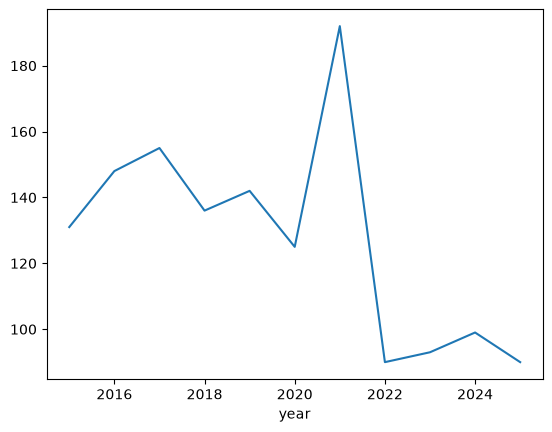

In [26]:
df_farmers['year'].value_counts().sort_index().plot()

In [27]:
df_farmers['job_satisfaction'].value_counts()

job_satisfaction
MOSTLY SATISFIED           314
NEUTRAL                    119
ABSOLUTELY SATISTFIED       93
NOT VERY SATISFIED          44
ABSOLUTELY UNSATISTFIED      7
NO ANSWER                    4
DOES NOT KNOW                2
Name: count, dtype: int64

<Axes: xlabel='year'>

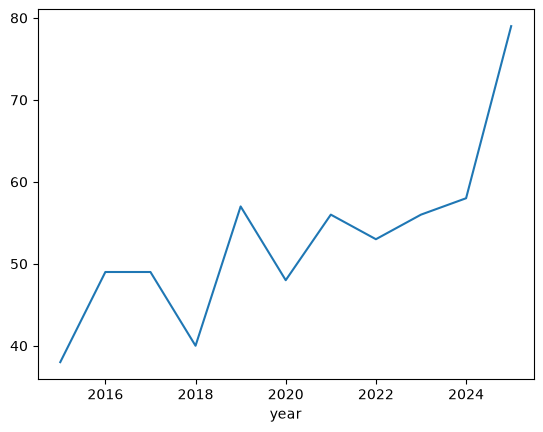

In [28]:
df_farmers[~df_farmers['job_satisfaction'].isna()]['year'].value_counts().sort_index().plot()

In [29]:
df_farmers[~df_farmers['job_satisfaction'].isna()]['year'].value_counts()

year
2025.0    79
2024.0    58
2019.0    57
2021.0    56
2023.0    56
2022.0    53
2016.0    49
2017.0    49
2020.0    48
2018.0    40
2015.0    38
Name: count, dtype: int64

In [ ]:
df_farmers['year'].value_counts().sort_index().plot()

In [17]:
df_farmers['primary_occupation'].value_counts()

primary_occupation
Working NOT at an enterprise, organization, collective farm, state farm, or coop    503
Temporarily not employed for other reasons and not looking for a job                286
A farmer                                                                            125
Temporarily not employed for other reasons and looking for a job                    122
Working at an enterprise, organization, collective farm, state farm, or cooperat    111
Retired and not working                                                             109
A housewife, caring for other family members, raising children                       88
An entrepreneur                                                                      48
Unable to work for health reasons, disabled                                           4
On official leave for looking after a child under 3 years old, not interrupting       3
Full-time University student                                                          2
Name: count, 

In [19]:
df_farmers[df_farmers['primary_occupation'] == 'A housewife, caring for other family members, raising children']#.to_excel()

,year,family_id,family_member_id,total_income_last30_days,job1_wage,job2_wage,iea_income,pension_benefit,age,gender,...,job_satisfaction,satisfaction_w_pay,satisfaction_w_ow,is_farmer,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status
3641,2015.0,6059.0,1.0,0.0,NaN,NaN,99999997.0,NaN,50.5,FEMALE,...,NaN,NaN,NaN,1,0.966538,NaN,1553,4,0,1
3923,2015.0,190.0,2.0,24500.0,NaN,NaN,24500.0,NaN,54.0,FEMALE,...,NaN,NaN,NaN,1,0.896978,120.0,1672,3,1,0
4656,2015.0,106.0,6.0,14500.0,NaN,NaN,14500.0,NaN,43.0,FEMALE,...,NaN,NaN,NaN,1,0.000000,6.0,1961,4,0,1
4682,2015.0,126.0,1.0,20000.0,NaN,NaN,20000.0,NaN,35.5,MALE,...,NaN,NaN,NaN,1,1.086592,96.0,1973,4,0,1
6694,2015.0,30.0,1.0,68000.0,NaN,NaN,68000.0,NaN,43.5,FEMALE,...,NaN,NaN,NaN,1,1.093191,NaN,2878,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139475,2024.0,77.0,3.0,0.0,NaN,NaN,18000.0,NaN,50.0,MALE,...,NaN,NaN,NaN,1,1.038956,NaN,59720,5,1,1
140291,2024.0,84.0,1.0,41400.0,NaN,NaN,41400.0,NaN,47.0,FEMALE,...,NaN,NaN,NaN,1,0.794879,NaN,60038,5,1,1
146373,2024.0,11710.0,1.0,30000.0,NaN,NaN,30000.0,NaN,49.0,FEMALE,...,NaN,NaN,NaN,1,0.906839,100.0,62706,4,1,0
148637,2025.0,223.0,1.0,40000.0,NaN,NaN,40000.0,NaN,48.0,FEMALE,...,NaN,NaN,NaN,1,0.833769,NaN,63713,3,0,1


In [257]:
farmers_selection = df_farmers['primary_occupation'].value_counts().head(4).index.tolist()
farmers_selection

['Working NOT at an enterprise, organization, collective farm, state farm, or coop',
 'An entrepreneur',
 'A farmer',
 'Working at an enterprise, organization, collective farm, state farm, or cooperat']

In [258]:
df_farmers['marst'].value_counts()

marst
In a registered marriage           53
Never married                      19
Living together, not registered    11
Divorsed and not remarried          5
Widower or widow                    2
Name: count, dtype: int64

In [259]:
df_farmers['diplom'].value_counts()

diplom
Secondary School Diploma                                            37
Higher education Diploma and more                                   30
Vocational secondary education Diploma                              13
Unfinished secondary education [7-8 grades of school] +smth else     7
Unfinished secondary education [7-8 grades of school]                3
Name: count, dtype: int64

In [260]:
df_farmers = df_farmers[df_farmers['primary_occupation'].isin(farmers_selection)]
df_farmers

,family_id,family_member_id,total_income_last30_days,age,gender,is_female,diplom,marst,children_num,settlement_type_born,...,primary_occupation,industry_job1,raised_and_sell_crops,is_farmer,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status
1115,325.0,3.0,50000.0,38.0,MALE,0,Higher education Diploma and more,In a registered marriage,2.0,IN A CITY,...,An entrepreneur,Agriculture,No,1,1.492625,168.0,479,4,1,1
1387,224.0,1.0,50000.0,56.5,MALE,0,Higher education Diploma and more,In a registered marriage,2.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,A farmer,Agriculture,No,1,1.034439,240.0,592,2,1,1
1851,75.0,1.0,20000.0,57.0,FEMALE,1,Vocational secondary education Diploma,Divorsed and not remarried,1.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,"Working NOT at an enterprise, organization, co...",Agriculture,No,1,0.867410,88.0,807,1,0,0
1881,105.0,4.0,50000.0,35.5,MALE,0,Higher education Diploma and more,In a registered marriage,3.0,NaN,...,A farmer,Agriculture,No,1,1.492625,35.0,818,6,1,1
1906,128.0,9.0,95000.0,49.0,MALE,0,Unfinished secondary education [7-8 grades of ...,In a registered marriage,1.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,"Working NOT at an enterprise, organization, co...",Agriculture,No,1,0.000000,NaN,827,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9534,171.0,3.0,60000.0,44.5,MALE,0,Higher education Diploma and more,In a registered marriage,1.0,IN A CITY,...,An entrepreneur,NaN,Yes,1,1.034439,NaN,4045,9,1,1
9535,171.0,4.0,60000.0,23.5,MALE,0,Higher education Diploma and more,In a registered marriage,1.0,NaN,...,An entrepreneur,NaN,Yes,1,0.979740,NaN,4045,9,1,1
9571,201.0,1.0,30000.0,44.5,FEMALE,1,Higher education Diploma and more,In a registered marriage,2.0,NaN,...,"Working NOT at an enterprise, organization, co...",Agriculture,Yes,1,1.062026,90.0,4058,4,1,1
9572,201.0,2.0,90000.0,47.5,MALE,0,Secondary School Diploma,In a registered marriage,2.0,NaN,...,"Working NOT at an enterprise, organization, co...",Agriculture,Yes,1,1.034439,224.0,4058,4,0,1


In [261]:
df_farmers.isna().sum()

family_id                    0
family_member_id             0
total_income_last30_days     0
age                          0
gender                       0
is_female                    0
diplom                       0
marst                        0
children_num                 0
settlement_type_born        57
region                       0
primary_occupation           0
industry_job1                3
raised_and_sell_crops        0
is_farmer                    0
inwgt                        0
hours_worked                23
family_id_imputed            0
family_size                  0
education_level              0
marital_status               0
dtype: int64

In [262]:
df_control = df[df['is_farmer'] == 0]
# df_control = df_control[df_control['settlement_type_born'].isin(['IN A CITY', 'IN AN URBAN-TYPE SETTLEMENT'])]
df_control

,family_id,family_member_id,total_income_last30_days,age,gender,is_female,diplom,marst,children_num,settlement_type_born,...,primary_occupation,industry_job1,raised_and_sell_crops,is_farmer,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status
0,13.0,1.0,40000.0,48.5,MALE,0,Secondary School Diploma,In a registered marriage,1.0,NaN,...,"Working at an enterprise, organization, collec...",Civil Machine Construction,No,0,0.000000,175.0,1,3,0,1
1,13.0,2.0,0.0,44.5,FEMALE,1,Vocational secondary education Diploma,In a registered marriage,1.0,NaN,...,"A housewife, caring for other family members, ...",NaN,No,0,0.000000,NaN,1,3,0,1
2,14.0,1.0,31000.0,76.5,FEMALE,1,Higher education Diploma and more,Widower or widow,1.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,Retired and not working,NaN,No,0,0.742500,NaN,2,1,1,0
3,16.0,1.0,35000.0,47.5,FEMALE,1,Secondary School Diploma,In a registered marriage,2.0,NaN,...,"Working at an enterprise, organization, collec...",Education,No,0,0.867410,154.0,3,3,0,1
4,16.0,2.0,80000.0,51.0,MALE,0,Vocational secondary education Diploma,In a registered marriage,2.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,"Working at an enterprise, organization, collec...",Military Industrial Complex,No,0,1.053314,156.0,3,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13550,90013.0,4.0,80000.0,20.5,FEMALE,1,Vocational secondary education Diploma,Never married,0.0,NaN,...,"Working at an enterprise, organization, collec...",Public Health,No,0,0.939756,192.0,5821,5,0,0
13551,90014.0,1.0,20100.0,66.5,FEMALE,1,Higher education Diploma and more,Widower or widow,2.0,IN AN URBAN-TYPE SETTLEMENT,...,Retired and not working,NaN,No,0,0.742500,NaN,5822,4,1,0
13552,90014.0,2.0,70000.0,38.0,FEMALE,1,Higher education Diploma and more,In a registered marriage,2.0,IN AN URBAN-TYPE SETTLEMENT,...,"Working at an enterprise, organization, collec...",Education,No,0,1.059966,168.0,5822,4,1,1
13553,90014.0,4.0,0.0,17.0,FEMALE,1,Unfinished secondary education [7-8 grades of ...,Never married,0.0,IN A CITY,...,Full time college student,NaN,No,0,0.939756,NaN,5822,4,0,0


In [263]:
df_control['settlement_type_born'].value_counts()

settlement_type_born
IN A CITY                               2372
IN A VILLAGE, DEREVNIA, KISHLAK, AUL    2215
IN AN URBAN-TYPE SETTLEMENT              890
NO ANSWER                                 13
Name: count, dtype: int64

In [264]:
df_ttl = pd.concat([df_control, df_farmers])
df_ttl

,family_id,family_member_id,total_income_last30_days,age,gender,is_female,diplom,marst,children_num,settlement_type_born,...,primary_occupation,industry_job1,raised_and_sell_crops,is_farmer,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status
0,13.0,1.0,40000.0,48.5,MALE,0,Secondary School Diploma,In a registered marriage,1.0,NaN,...,"Working at an enterprise, organization, collec...",Civil Machine Construction,No,0,0.000000,175.0,1,3,0,1
1,13.0,2.0,0.0,44.5,FEMALE,1,Vocational secondary education Diploma,In a registered marriage,1.0,NaN,...,"A housewife, caring for other family members, ...",NaN,No,0,0.000000,NaN,1,3,0,1
2,14.0,1.0,31000.0,76.5,FEMALE,1,Higher education Diploma and more,Widower or widow,1.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,Retired and not working,NaN,No,0,0.742500,NaN,2,1,1,0
3,16.0,1.0,35000.0,47.5,FEMALE,1,Secondary School Diploma,In a registered marriage,2.0,NaN,...,"Working at an enterprise, organization, collec...",Education,No,0,0.867410,154.0,3,3,0,1
4,16.0,2.0,80000.0,51.0,MALE,0,Vocational secondary education Diploma,In a registered marriage,2.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,"Working at an enterprise, organization, collec...",Military Industrial Complex,No,0,1.053314,156.0,3,3,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9534,171.0,3.0,60000.0,44.5,MALE,0,Higher education Diploma and more,In a registered marriage,1.0,IN A CITY,...,An entrepreneur,NaN,Yes,1,1.034439,NaN,4045,9,1,1
9535,171.0,4.0,60000.0,23.5,MALE,0,Higher education Diploma and more,In a registered marriage,1.0,NaN,...,An entrepreneur,NaN,Yes,1,0.979740,NaN,4045,9,1,1
9571,201.0,1.0,30000.0,44.5,FEMALE,1,Higher education Diploma and more,In a registered marriage,2.0,NaN,...,"Working NOT at an enterprise, organization, co...",Agriculture,Yes,1,1.062026,90.0,4058,4,1,1
9572,201.0,2.0,90000.0,47.5,MALE,0,Secondary School Diploma,In a registered marriage,2.0,NaN,...,"Working NOT at an enterprise, organization, co...",Agriculture,Yes,1,1.034439,224.0,4058,4,0,1


In [265]:
df_ttl['region'].unique().tolist()

['Leningrad Oblast: Volosovkij Rajon',
 'Krasnodar CR',
 'Udmurt ASSR: Glasov CR',
 'Perm Territory: Solikamsk City & Rajon',
 'Kaluzhskaya Oblast: Kuibyshev Rajon',
 'Tambov Oblast: Uvarovo CR',
 'Volgograd Oblast: Rudnjanskij Rajon',
 'Tatarskaja ASSR: Kazan',
 'Kurgan',
 'Orenburg Oblast: Orsk',
 'Chuvashskaya ASSR: Shumerlja CR',
 'Stavropolskij Kraj: Georgievskij CR',
 'Altaiskij Kraj: Kur`inskij Rajon',
 'Krasnojarskij Kraij: Krasnojarsk',
 'Kalinin Oblast: Rzhev CR',
 'Saratov CR',
 'Tomsk',
 'Lipetskaya Oblast: Lipetsk CR',
 'Krasnojarskij Kraij: Nazarovo CR',
 'Kabardino-Balkarija, Zol `skij Rajon',
 'Altaiskij Kraj: Biisk CR',
 'Vladivostok',
 'Amurskaja Oblast: Tambovskii Rajon',
 'Saratov Oblast: Volskij Gorosovet & Rajon',
 'Komi-ASSR: Syktyvkar',
 'Cheliabinsk',
 'Cheliabinsk Oblast:  Krasnoarmeiskij Rajon',
 'Gorkovskaja Oblast: Nizhnij Novgorod',
 'Penzenskaya Oblast: Zemetchinskij Rajon',
 'Krasnodarskij Kraj: Kushchevskij Rajon',
 'Smolensk CR',
 'Tulskaja Oblast: Tul

In [266]:
df_ttl['total_income_last30_days'].describe()

count    1.354600e+04
mean     4.518859e+04
std      5.112832e+04
min      0.000000e+00
25%      2.000000e+04
50%      3.500000e+04
75%      6.000000e+04
max      2.000000e+06
Name: total_income_last30_days, dtype: float64

In [267]:
df_ttl['total_income_last30_days'].quantile(0.95)

np.float64(120000.0)

In [268]:
6.000000e+04

60000.0

<Axes: ylabel='Density'>

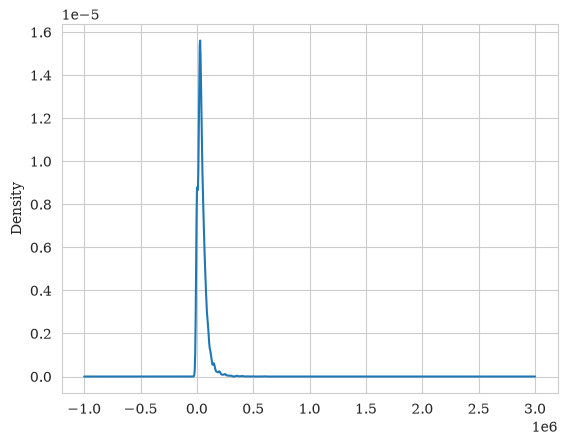

In [269]:
df_ttl['total_income_last30_days'].plot.kde()

In [270]:
df_ttl = df_ttl[
    (df_ttl['total_income_last30_days'] <= 200_000) &
    (df_ttl['total_income_last30_days'] != 0) & 
    (df_ttl['inwgt'] != 0)
]

<Axes: ylabel='Density'>

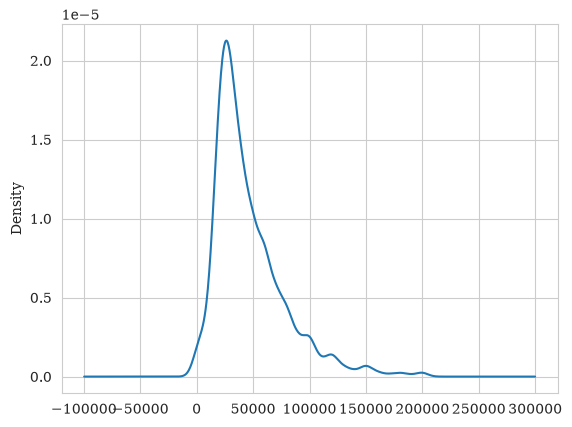

In [271]:
df_ttl['total_income_last30_days'].plot.kde()

In [272]:
df_ttl = df_ttl.rename(columns={'total_income_last30_days':'ttl_income'})

# data desc

In [199]:
import numpy as np
import pandas as pd

def weighted_stats(df, cols, weight_col):
    rows = []
    w = df[weight_col].values
    w_sum = w.sum()
    for col in cols:
        x = df[col].values
        mask = ~np.isnan(x) & ~np.isnan(w)
        xv, wv = x[mask], w[mask]
        wsum = wv.sum()

        mean = np.sum(xv * wv) / wsum

        # Weighted variance (frequency-weight style, consistent with survey packages)
        var = np.sum(wv * (xv - mean) ** 2) / wsum
        std = np.sqrt(var)

        # Weighted median: point where cumulative weight crosses 50%
        order = np.argsort(xv)
        x_sorted, w_sorted = xv[order], wv[order]
        cum_w = np.cumsum(w_sorted)
        median = x_sorted[np.searchsorted(cum_w, 0.5 * wsum)]

        rows.append({
            'statistic': col,
            'count': len(xv),          # unweighted N
            'weight_sum': wsum,        # weighted N
            'mean': mean,
            'std': std,
            'min': xv.min(),
            'max': xv.max(),
            'median': median,
        })
    return pd.DataFrame(rows).set_index('statistic')

cols = ['ttl_income', 'age', 'is_female', 'family_size',
        'education_level', 'marital_status', 'is_farmer']

desc_table = weighted_stats(df_ttl, cols, 'inwgt').round(2)

In [200]:
desc_table = df_ttl[['ttl_income', 'age', 'is_female', 'family_size', 'education_level', 'marital_status', 'is_farmer']].describe().T.drop(columns=['25%', '50%', '75%'])
desc_table = desc_table.round(2)
desc_table['count'] = desc_table['count'].astype(int)
desc_table['min'] = desc_table['min'].astype(int)
desc_table['max'] = desc_table['max'].astype(int)
desc_table = desc_table.reset_index(names='statistic')
desc_table

,statistic,count,mean,std,min,max
0,ttl_income,2289,50630.17,33671.99,491,200000
1,age,2289,53.84,17.79,14,98
2,is_female,2289,0.62,0.49,0,1
3,family_size,2289,3.34,2.06,1,15
4,education_level,2289,0.36,0.48,0,1
5,marital_status,2289,0.60,0.49,0,1
6,is_farmer,2289,0.03,0.17,0,1


In [201]:
desc_table = weighted_stats(df_ttl, cols, 'inwgt').round(2)
desc_table

,count,weight_sum,mean,std,min,max,median
statistic,,,,,,,
ttl_income,2289,2151.74,52542.28,34669.48,491.0,200000.0,43215.0
age,2289,2151.74,51.82,17.60,14.0,98.5,50.5
is_female,2289,2151.74,0.57,0.50,0.0,1.0,1.0
family_size,2289,2151.74,3.43,2.08,1.0,15.0,3.0
education_level,2289,2151.74,0.36,0.48,0.0,1.0,0.0
marital_status,2289,2151.74,0.63,0.48,0.0,1.0,1.0
is_farmer,2289,2151.74,0.04,0.18,0.0,1.0,0.0


In [202]:
print(pl.from_pandas(desc_table))

shape: (7, 7)
┌───────┬────────────┬──────────┬──────────┬───────┬──────────┬─────────┐
│ count ┆ weight_sum ┆ mean     ┆ std      ┆ min   ┆ max      ┆ median  │
│ ---   ┆ ---        ┆ ---      ┆ ---      ┆ ---   ┆ ---      ┆ ---     │
│ i64   ┆ f64        ┆ f64      ┆ f64      ┆ f64   ┆ f64      ┆ f64     │
╞═══════╪════════════╪══════════╪══════════╪═══════╪══════════╪═════════╡
│ 2289  ┆ 2151.74    ┆ 52542.28 ┆ 34669.48 ┆ 491.0 ┆ 200000.0 ┆ 43215.0 │
│ 2289  ┆ 2151.74    ┆ 51.82    ┆ 17.6     ┆ 14.0  ┆ 98.5     ┆ 50.5    │
│ 2289  ┆ 2151.74    ┆ 0.57     ┆ 0.5      ┆ 0.0   ┆ 1.0      ┆ 1.0     │
│ 2289  ┆ 2151.74    ┆ 3.43     ┆ 2.08     ┆ 1.0   ┆ 15.0     ┆ 3.0     │
│ 2289  ┆ 2151.74    ┆ 0.36     ┆ 0.48     ┆ 0.0   ┆ 1.0      ┆ 0.0     │
│ 2289  ┆ 2151.74    ┆ 0.63     ┆ 0.48     ┆ 0.0   ┆ 1.0      ┆ 1.0     │
│ 2289  ┆ 2151.74    ┆ 0.04     ┆ 0.18     ┆ 0.0   ┆ 1.0      ┆ 0.0     │
└───────┴────────────┴──────────┴──────────┴───────┴──────────┴─────────┘


In [203]:
desc_table = df_ttl[df_ttl['is_farmer'] == 1]
desc_table = desc_table[['ttl_income', 'age', 'is_female', 'family_size', 'education_level', 'marital_status']].describe().T.drop(columns=['25%', '50%', '75%'])
desc_table = desc_table.round(2)
desc_table['count'] = desc_table['count'].astype(int)
desc_table['min'] = desc_table['min'].astype(int)
desc_table['max'] = desc_table['max'].astype(int)
desc_table = desc_table.reset_index(names='statistic')
desc_table

,statistic,count,mean,std,min,max
0,ttl_income,68,55348.53,29717.99,12300,173000
1,age,68,44.93,12.31,21,66
2,is_female,68,0.25,0.44,0,1
3,family_size,68,4.57,1.74,1,9
4,education_level,68,0.34,0.48,0,1
5,marital_status,68,0.66,0.48,0,1


In [204]:
desc_table = weighted_stats(df_ttl[df_ttl['is_farmer'] == 1], cols, 'inwgt').round(2)
desc_table

,count,weight_sum,mean,std,min,max,median
statistic,,,,,,,
ttl_income,68,76.09,55304.16,28776.75,12300.0,173000.0,49900.0
age,68,76.09,44.04,11.80,21.5,66.5,44.0
is_female,68,76.09,0.21,0.41,0.0,1.0,0.0
family_size,68,76.09,4.63,1.65,1.0,9.0,4.0
education_level,68,76.09,0.34,0.47,0.0,1.0,0.0
marital_status,68,76.09,0.65,0.48,0.0,1.0,1.0
is_farmer,68,76.09,1.00,0.00,1.0,1.0,1.0


In [205]:
print(pl.from_pandas(desc_table))

shape: (7, 7)
┌───────┬────────────┬──────────┬──────────┬─────────┬──────────┬─────────┐
│ count ┆ weight_sum ┆ mean     ┆ std      ┆ min     ┆ max      ┆ median  │
│ ---   ┆ ---        ┆ ---      ┆ ---      ┆ ---     ┆ ---      ┆ ---     │
│ i64   ┆ f64        ┆ f64      ┆ f64      ┆ f64     ┆ f64      ┆ f64     │
╞═══════╪════════════╪══════════╪══════════╪═════════╪══════════╪═════════╡
│ 68    ┆ 76.09      ┆ 55304.16 ┆ 28776.75 ┆ 12300.0 ┆ 173000.0 ┆ 49900.0 │
│ 68    ┆ 76.09      ┆ 44.04    ┆ 11.8     ┆ 21.5    ┆ 66.5     ┆ 44.0    │
│ 68    ┆ 76.09      ┆ 0.21     ┆ 0.41     ┆ 0.0     ┆ 1.0      ┆ 0.0     │
│ 68    ┆ 76.09      ┆ 4.63     ┆ 1.65     ┆ 1.0     ┆ 9.0      ┆ 4.0     │
│ 68    ┆ 76.09      ┆ 0.34     ┆ 0.47     ┆ 0.0     ┆ 1.0      ┆ 0.0     │
│ 68    ┆ 76.09      ┆ 0.65     ┆ 0.48     ┆ 0.0     ┆ 1.0      ┆ 1.0     │
│ 68    ┆ 76.09      ┆ 1.0      ┆ 0.0      ┆ 1.0     ┆ 1.0      ┆ 1.0     │
└───────┴────────────┴──────────┴──────────┴─────────┴──────────┴─────────

# models

# OLS

In [226]:
model1 = smf.wls("np.log1p(ttl_income) ~ age + I(age**2) + is_female + education_level + marital_status + family_size", data=df_ttl, weights=df_ttl['inwgt']).fit(cov_type="HC3")
print(model1.get_robustcov_results(cov_type="HC3").summary2())

                   Results: Weighted least squares
Model:              WLS                  Adj. R-squared:     0.190    
Dependent Variable: np.log1p(ttl_income) AIC:                4403.9419
Date:               2026-10-20 14:30     BIC:                4444.0929
No. Observations:   2289                 Log-Likelihood:     -2195.0  
Df Model:           6                    F-statistic:        91.77    
Df Residuals:       2282                 Prob (F-statistic): 1.92e-103
R-squared:          0.192                Scale:              0.37060  
-----------------------------------------------------------------------
                    Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
-----------------------------------------------------------------------
Intercept           9.8139    0.1715  57.2275  0.0000   9.4778  10.1500
age                 0.0465    0.0064   7.2956  0.0000   0.0340   0.0590
I(age ** 2)        -0.0005    0.0001  -8.8595  0.0000  -0.0006  -0.0004
is_female          -

In [227]:
farmers_ttl = df_ttl[df_ttl['is_farmer'] == 1]
farmers_ttl

,family_id,family_member_id,ttl_income,age,gender,is_female,diplom,marst,children_num,settlement_type_born,...,is_farmer,inwgt,hours_worked,family_id_imputed,family_size,education_level,marital_status,diplom_short,is_farmer_str,log_income
1115,325.0,3.0,50000.0,38.0,MALE,0,Higher education Diploma and more,In a registered marriage,2.0,IN A CITY,...,1,1.492625,168.0,479,4,1,1,Высшее,1,10.819798
1387,224.0,1.0,50000.0,56.5,MALE,0,Higher education Diploma and more,In a registered marriage,2.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,1,1.034439,240.0,592,2,1,1,Высшее,1,10.819798
1851,75.0,1.0,20000.0,57.0,FEMALE,1,Vocational secondary education Diploma,Divorsed and not remarried,1.0,"IN A VILLAGE, DEREVNIA, KISHLAK, AUL",...,1,0.867410,88.0,807,1,0,0,Среднее спец.,1,9.903538
1881,105.0,4.0,50000.0,35.5,MALE,0,Higher education Diploma and more,In a registered marriage,3.0,NaN,...,1,1.492625,35.0,818,6,1,1,Высшее,1,10.819798
1920,136.0,2.0,46200.0,59.5,FEMALE,1,Secondary School Diploma,Never married,0.0,NaN,...,1,0.833769,144.0,831,2,0,0,Среднее общее,1,10.740757
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9532,171.0,1.0,173000.0,66.5,MALE,0,Higher education Diploma and more,In a registered marriage,2.0,IN AN URBAN-TYPE SETTLEMENT,...,1,1.037976,NaN,4045,9,1,1,Высшее,1,12.061053
9534,171.0,3.0,60000.0,44.5,MALE,0,Higher education Diploma and more,In a registered marriage,1.0,IN A CITY,...,1,1.034439,NaN,4045,9,1,1,Высшее,1,11.002117
9535,171.0,4.0,60000.0,23.5,MALE,0,Higher education Diploma and more,In a registered marriage,1.0,NaN,...,1,0.979740,NaN,4045,9,1,1,Высшее,1,11.002117
9571,201.0,1.0,30000.0,44.5,FEMALE,1,Higher education Diploma and more,In a registered marriage,2.0,NaN,...,1,1.062026,90.0,4058,4,1,1,Высшее,1,10.308986


/var/folders/3k/2g_xrgp509qd4562wzk378jc0000gp/T/ipykernel_1970/1395382894.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ttl, x='is_farmer_str', y='log_income',
/var/folders/3k/2g_xrgp509qd4562wzk378jc0000gp/T/ipykernel_1970/1395382894.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax3.set_xticklabels(['Нефермеры', 'Фермеры'])
/var/folders/3k/2g_xrgp509qd4562wzk378jc0000gp/T/ipykernel_1970/1395382894.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ttl, x='is_farmer_str', y='family_size',
/var/folders/3k/2g_xrgp509qd4562wzk378jc0000gp/T/ip

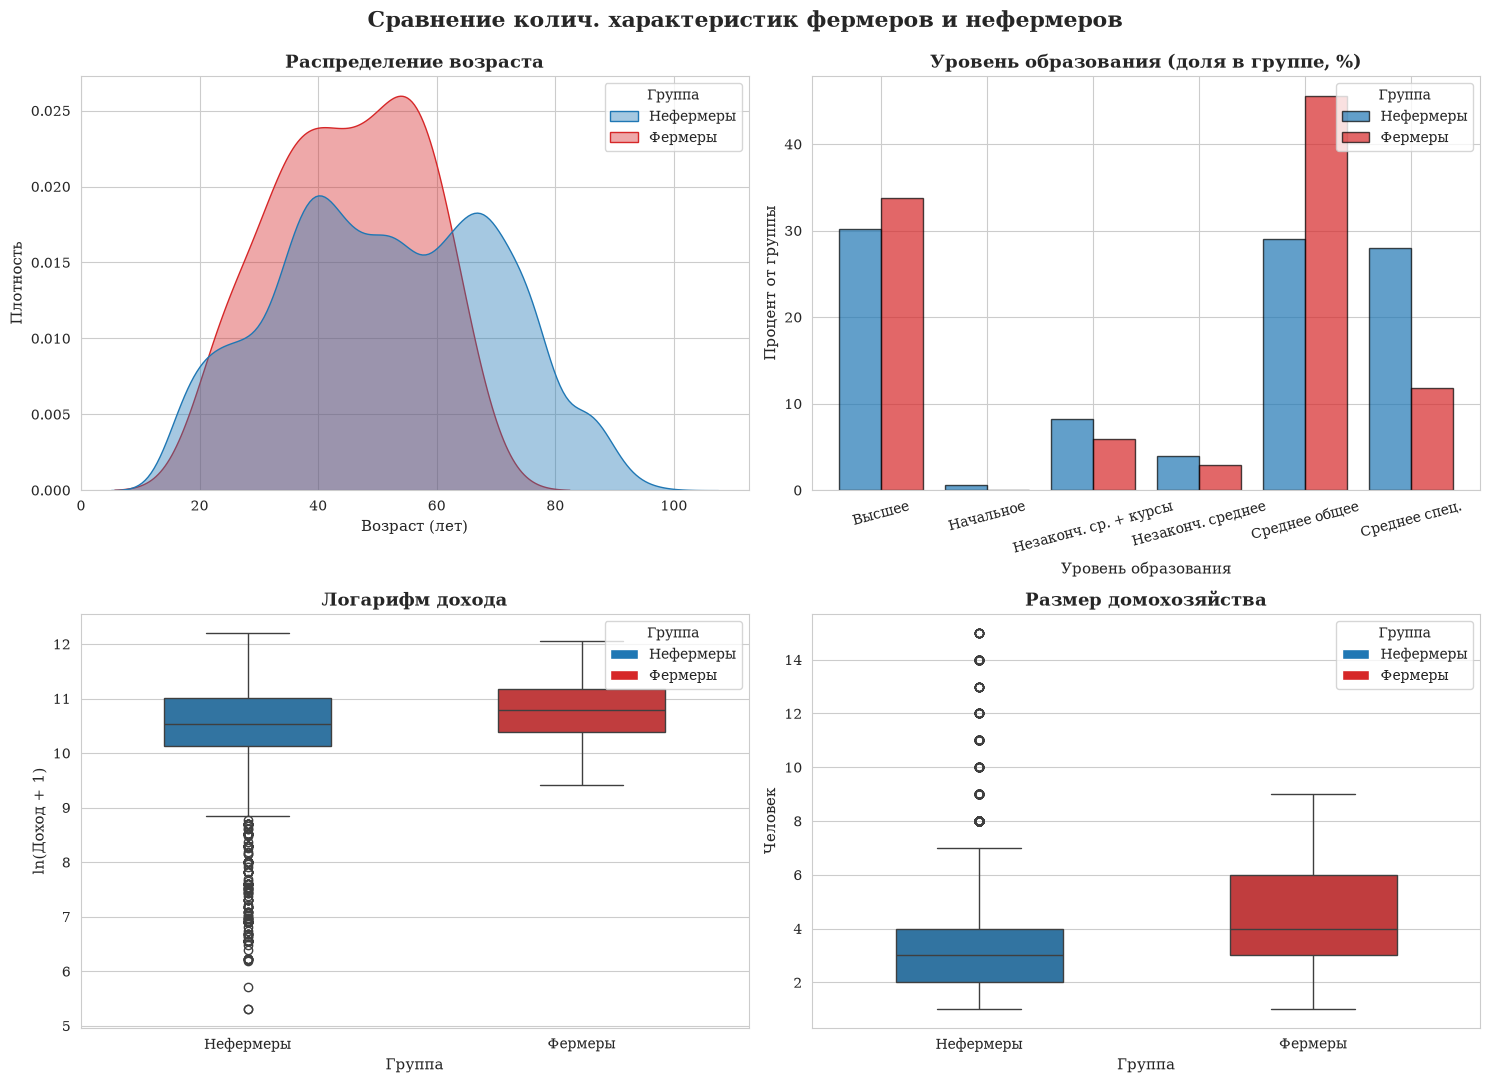

In [273]:
from matplotlib.patches import Patch
diplom_short = {
    'Higher education Diploma and more': 'Высшее',
    'Secondary School Diploma': 'Среднее общее',
    'Vocational secondary education Diploma': 'Среднее спец.',
    'Unfinished secondary education [7-8 grades of school] +smth else': 'Незаконч. ср. + курсы',
    'Unfinished secondary education [7-8 grades of school]': 'Незаконч. среднее',
    '0-6 grades of comprehensive school': 'Начальное'
}

# Apply mapping to df_ttl
df_ttl['diplom_short'] = df_ttl['diplom'].map(diplom_short).fillna(df_ttl['diplom'])

# Ensure is_farmer is treated as string for plotting consistency
df_ttl['is_farmer_str'] = df_ttl['is_farmer'].astype(str)

# Set style
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'serif'

# Create figure and axes
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Сравнение колич. характеристик фермеров и нефермеров', 
             fontsize=16, fontweight='bold', y=0.98)

# ---------------------------------------------------------
# Plot 1: Age comparison (KDE)
# ---------------------------------------------------------
ax1 = axes[0, 0]
sns.kdeplot(data=df_ttl, x='age', hue='is_farmer_str', 
            common_norm=False, ax=ax1, palette={'0': '#1f77b4', '1': '#d62728'}, 
            fill=True, alpha=0.4)

ax1.set_title('Распределение возраста', fontsize=13, fontweight='bold')
ax1.set_xlabel('Возраст (лет)', fontsize=11)
ax1.set_ylabel('Плотность', fontsize=11)

# Robust legend handling for Plot 1
if ax1.legend_ is not None:
    legend = ax1.legend_
    legend.set_title('Группа')
    for text, label in zip(legend.get_texts(), ['Нефермеры', 'Фермеры']):
        text.set_text(label)

# ---------------------------------------------------------
# Plot 2: Education (Grouped Transparent Bar Chart)
# ---------------------------------------------------------
ax2 = axes[0, 1]
edu_counts = df_ttl.groupby(['diplom_short', 'is_farmer']).size().unstack(fill_value=0)
edu_props = edu_counts.div(edu_counts.sum(axis=0), axis=1) * 100

edu_props.plot(kind='bar', ax=ax2, color=['#1f77b4', '#d62728'], 
               alpha=0.7, edgecolor='black', width=0.8)

ax2.set_title('Уровень образования (доля в группе, %)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Уровень образования', fontsize=11)
ax2.set_ylabel('Процент от группы', fontsize=11)
ax2.tick_params(axis='x', rotation=15)
ax2.legend(['Нефермеры', 'Фермеры'], title='Группа', loc='upper right')

# ---------------------------------------------------------
# Plot 3: Income comparison (Boxplot)
# ---------------------------------------------------------
ax3 = axes[1, 0]
df_ttl['log_income'] = np.log1p(df_ttl['ttl_income'])
sns.boxplot(data=df_ttl, x='is_farmer_str', y='log_income', 
            ax=ax3, palette={'0': '#1f77b4', '1': '#d62728'}, width=0.5)

ax3.set_title('Логарифм дохода', fontsize=13, fontweight='bold')
ax3.set_xlabel('Группа', fontsize=11)
ax3.set_ylabel('ln(Доход + 1)', fontsize=11)
ax3.set_xticklabels(['Нефермеры', 'Фермеры'])

legend_elements = [Patch(facecolor='#1f77b4', label='Нефермеры'),
                   Patch(facecolor='#d62728', label='Фермеры')]
ax3.legend(handles=legend_elements, title='Группа', loc='upper right')

# ---------------------------------------------------------
# Plot 4: Family size (Boxplot)
# ---------------------------------------------------------
ax4 = axes[1, 1]
sns.boxplot(data=df_ttl, x='is_farmer_str', y='family_size', 
            ax=ax4, palette={'0': '#1f77b4', '1': '#d62728'}, width=0.5)

ax4.set_title('Размер домохозяйства', fontsize=13, fontweight='bold')
ax4.set_xlabel('Группа', fontsize=11)
ax4.set_ylabel('Человек', fontsize=11)
ax4.set_xticklabels(['Нефермеры', 'Фермеры'])

ax4.legend(handles=legend_elements, title='Группа', loc='upper right')

# ---------------------------------------------------------
# Adjust layout and save
# ---------------------------------------------------------
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig('farmers_vs_controls_updated.png', dpi=300, bbox_inches='tight')
plt.show()

In [229]:
farmers_ttl['marital_status'].value_counts(normalize=True)

marital_status
1    0.661765
0    0.338235
Name: proportion, dtype: float64

In [230]:
farmers_ttl['sells_crops'] = np.where(farmers_ttl['raised_and_sell_crops'] == 'Yes', 1, 0)

In [231]:
farmers_ttl['primary_occupation'].value_counts()

primary_occupation
Working NOT at an enterprise, organization, collective farm, state farm, or coop    50
An entrepreneur                                                                     11
A farmer                                                                             5
Working at an enterprise, organization, collective farm, state farm, or cooperat     2
Name: count, dtype: int64

In [232]:
# C(region, Treatment(reference='Moscow City'))
model2 = smf.wls("np.log1p(ttl_income) ~ age + I(age**2) + is_female + education_level + marital_status + family_size", data=farmers_ttl, weights=farmers_ttl['inwgt']).fit(cov_type="HC3")
print(model2.get_robustcov_results(cov_type="HC3").summary2())

                   Results: Weighted least squares
Model:              WLS                  Adj. R-squared:     0.092   
Dependent Variable: np.log1p(ttl_income) AIC:                98.2563 
Date:               2026-10-20 14:30     BIC:                113.7928
No. Observations:   68                   Log-Likelihood:     -42.128 
Df Model:           6                    F-statistic:        2.389   
Df Residuals:       61                   Prob (F-statistic): 0.0387  
R-squared:          0.173                Scale:              0.24780 
----------------------------------------------------------------------
                   Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
----------------------------------------------------------------------
Intercept          9.9744    0.7535  13.2382  0.0000   8.4977  11.4512
age                0.0103    0.0370   0.2777  0.7812  -0.0622   0.0827
I(age ** 2)       -0.0001    0.0004  -0.1911  0.8484  -0.0010   0.0008
is_female          0.0654    0.15

In [233]:
print(model2.get_robustcov_results(cov_type="HC3").summary2().as_latex())

\begin{table}
\caption{Results: Weighted least squares}
\label{}
\begin{center}
\begin{tabular}{llll}
\hline
Model:              & WLS                   & Adj. R-squared:     & 0.092     \\
Dependent Variable: & np.log1p(ttl\_income) & AIC:                & 98.2563   \\
Date:               & 2026-10-20 14:30      & BIC:                & 113.7928  \\
No. Observations:   & 68                    & Log-Likelihood:     & -42.128   \\
Df Model:           & 6                     & F-statistic:        & 2.389     \\
Df Residuals:       & 61                    & Prob (F-statistic): & 0.0387    \\
R-squared:          & 0.173                 & Scale:              & 0.24780   \\
\hline
\end{tabular}
\end{center}

\begin{center}
\begin{tabular}{lrrrrrr}
\hline
                 &   Coef. & Std.Err. &       z & P$> |$z$|$ &  [0.025 &  0.975]  \\
\hline
Intercept        &  9.9744 &   0.7535 & 13.2382 &      0.0000 &  8.4977 & 11.4512  \\
age              &  0.0103 &   0.0370 &  0.2777 &      0.7812 & 

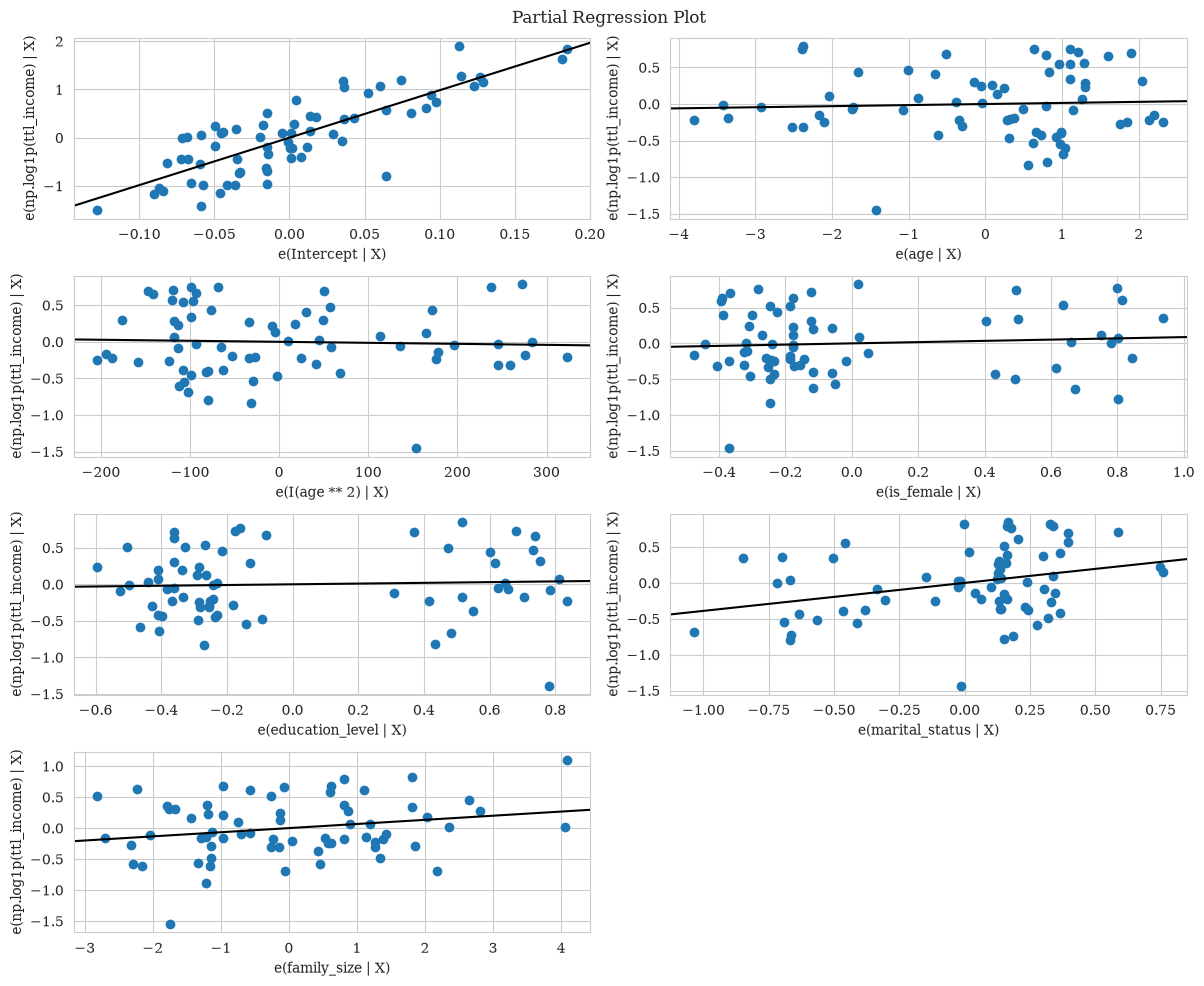

In [234]:

fig = sm.graphics.plot_partregress_grid(model2)
fig.set_size_inches(12, 10) 
fig.tight_layout(pad=1.0)
fig.savefig('regression_diagnistics.png')

In [274]:
y_farm = np.log1p(farmers_ttl['ttl_income'])
farmers_ttl['age_sq'] = farmers_ttl['age'] ** 2
X_farm = sm.add_constant(farmers_ttl[['age', 'age_sq', 'is_female', 'education_level', 'marital_status', 'family_size']])
X_farm

,const,age,age_sq,is_female,education_level,marital_status,family_size
1115,1.0,38.0,1444.00,0,1,1,4
1387,1.0,56.5,3192.25,0,1,1,2
1851,1.0,57.0,3249.00,1,0,0,1
1881,1.0,35.5,1260.25,0,1,1,6
1920,1.0,59.5,3540.25,1,0,0,2
...,...,...,...,...,...,...,...
9532,1.0,66.5,4422.25,0,1,1,9
9534,1.0,44.5,1980.25,0,1,1,9
9535,1.0,23.5,552.25,0,1,1,9
9571,1.0,44.5,1980.25,1,1,1,4


In [275]:
model_chk = sm.OLS(y_farm, X_farm).fit()
y_hat = model_chk.predict(X_farm)

X_link = sm.add_constant(pd.DataFrame({'y_hat': y_hat, 'y_hat_sq': y_hat**2}))
link_model = sm.OLS(y_farm, X_link).fit()

print(link_model.summary2())

                Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.166  
Dependent Variable: ttl_income       AIC:                91.4717
Date:               2026-10-20 15:03 BIC:                98.1303
No. Observations:   68               Log-Likelihood:     -42.736
Df Model:           2                F-statistic:        7.685  
Df Residuals:       65               Prob (F-statistic): 0.00101
R-squared:          0.191            Scale:              0.21528
-----------------------------------------------------------------
           Coef.   Std.Err.     t     P>|t|     [0.025    0.975] 
-----------------------------------------------------------------
const     45.0927  122.8178   0.3672  0.7147  -200.1915  290.3769
y_hat     -7.3735   22.8022  -0.3234  0.7475   -52.9127   38.1657
y_hat_sq   0.3886    1.0581   0.3672  0.7146    -1.7245    2.5016
----------------------------------------------------------------
Omnibus:             0.861        Du

In [276]:
control_ttl = df_ttl[df_ttl['is_farmer'] == 0]

In [277]:
model3 = smf.ols("np.log1p(ttl_income) ~ age + I(age**2) + is_female + education_level + marital_status + family_size", data=control_ttl, weights=control_ttl['inwgt']).fit(cov_type="HC3")
print(model3.get_robustcov_results(cov_type="HC3").summary2())

                    Results: Ordinary least squares
Model:              OLS                  Adj. R-squared:     0.177     
Dependent Variable: np.log1p(ttl_income) AIC:                18496.6817
Date:               2026-10-20 15:03     BIC:                18546.2130
No. Observations:   8742                 Log-Likelihood:     -9241.3   
Df Model:           6                    F-statistic:        261.8     
Df Residuals:       8735                 Prob (F-statistic): 4.66e-309 
R-squared:          0.177                Scale:              0.48537   
------------------------------------------------------------------------
                    Coef.   Std.Err.     z      P>|z|    [0.025   0.975]
------------------------------------------------------------------------
Intercept           9.1946    0.0972   94.6312  0.0000   9.0042   9.3851
age                 0.0603    0.0035   17.0356  0.0000   0.0534   0.0673
I(age ** 2)        -0.0006    0.0000  -18.9054  0.0000  -0.0006  -0.0005
is_fem

/opt/anaconda3/envs/creeper/lib/python3.14/site-packages/statsmodels/base/model.py:243: ValueWarning: Weights are not supported in OLS and will be ignoredAn exception will be raised in the next version.
  mod = cls(endog, exog, *args, **kwargs)
/opt/anaconda3/envs/creeper/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:1045: ValueWarning: unknown kwargs ['weights']
  self._check_kwargs(kwargs, ["offset"])


In [278]:
?summary_col

Signature:
summary_col(
    results,
    float_format='%.4f',
    model_names=(),
    stars=False,
    info_dict=None,
    regressor_order=(),
    drop_omitted=False,
    include_r2=True,
    fixed_effects=None,
    fe_present='Yes',
    fe_absent='',
)
Docstring:
Summarize multiple results instances side-by-side (coefs and SEs)

Parameters
----------
results : statsmodels results instance or list of result instances
    The results to summarize side-by-side.
float_format : str, optional
    float format for coefficients and standard errors
    Default : '%.4f'
model_names : list of str, optional
    Must have same length as the number of results. If the names are not
    unique, a roman number will be appended to all model names
stars : bool, optional
    print significance stars
info_dict : dict, optional
    dict of functions to be applied to results instances to retrieve
    model info. To use specific information for different models, add a
    (nested) info_dict with model name a

In [279]:
model1.f_pvalue

np.float64(1.9167151188832337e-103)

In [280]:
.1783 / .2776

0.6422910662824207

In [305]:
info_dict = {
    "N": lambda x: f"{int(x.nobs)}",
    'F-statistic': lambda x: f"{x.fvalue:.4f}",
    'F-stat. p-value': lambda x: f"{x.f_pvalue:.4f}"
}

table = summary_col(
    [model1, model2, model3],
    model_names=["(1) total", "(2) farmers", '(3) control'],
    stars=True,
    info_dict=info_dict,
)
print(table)


                (1) total  (2) farmers (3) control
--------------------------------------------------
Intercept       9.8139***  9.9744***   9.1946***  
                (0.1715)   (0.7535)    (0.0972)   
age             0.0465***  0.0103      0.0603***  
                (0.0064)   (0.0370)    (0.0035)   
I(age ** 2)     -0.0005*** -0.0001     -0.0006*** 
                (0.0001)   (0.0004)    (0.0000)   
is_female       -0.2725*** 0.0654      -0.2064*** 
                (0.0290)   (0.1551)    (0.0166)   
education_level 0.3144***  0.0883      0.3516***  
                (0.0264)   (0.1399)    (0.0147)   
marital_status  0.0883***  0.3586**    0.1152***  
                (0.0300)   (0.1516)    (0.0158)   
family_size     -0.0246*** 0.0587      -0.0215*** 
                (0.0073)   (0.0464)    (0.0049)   
R-squared       0.1924     0.1733      0.1772     
R-squared Adj.  0.1903     0.0919      0.1766     
F-stat. p-value 0.0000     0.0387      0.0000     
F-statistic     91.7737    2.3

In [304]:
10.7936 - 10.5160

0.2775999999999996

In [282]:
print(table.as_latex())

\begin{table}
\caption{}
\label{}
\begin{center}
\begin{tabular}{llll}
\hline
                 & (1) total  & (2) farmers & (3) control  \\
\hline
Intercept        & 9.8139***  & 9.9744***   & 9.1946***    \\
                 & (0.1715)   & (0.7535)    & (0.0972)     \\
age              & 0.0465***  & 0.0103      & 0.0603***    \\
                 & (0.0064)   & (0.0370)    & (0.0035)     \\
I(age ** 2)      & -0.0005*** & -0.0001     & -0.0006***   \\
                 & (0.0001)   & (0.0004)    & (0.0000)     \\
is\_female       & -0.2725*** & 0.0654      & -0.2064***   \\
                 & (0.0290)   & (0.1551)    & (0.0166)     \\
education\_level & 0.3144***  & 0.0883      & 0.3516***    \\
                 & (0.0264)   & (0.1399)    & (0.0147)     \\
marital\_status  & 0.0883***  & 0.3586**    & 0.1152***    \\
                 & (0.0300)   & (0.1516)    & (0.0158)     \\
family\_size     & -0.0246*** & 0.0587      & -0.0215***   \\
                 & (0.0073)   & (0.0464)    & (

# decomposition ttl

In [283]:
endog = np.log1p(df_ttl['ttl_income'])
endog

2       10.341775
3       10.463132
4       11.289794
5       11.002117
6       10.165890
          ...    
9532    12.061053
9534    11.002117
9535    11.002117
9571    10.308986
9572    11.407576
Name: ttl_income, Length: 8810, dtype: float64

In [288]:
exog = df_ttl[['age', 'is_female', 'education_level', 'marital_status', 'family_size', 'is_farmer']]
exog['age_sq'] = exog['age'] ** 2
exog

,age,is_female,education_level,marital_status,family_size,is_farmer,age_sq
2,76.5,1,1,0,1,0,5852.25
3,47.5,1,0,1,3,0,2256.25
4,51.0,0,0,1,3,0,2601.00
5,25.5,1,0,0,3,0,650.25
6,66.0,1,0,0,3,0,4356.00
...,...,...,...,...,...,...,...
9532,66.5,0,1,1,9,1,4422.25
9534,44.5,0,1,1,9,1,1980.25
9535,23.5,0,1,1,9,1,552.25
9571,44.5,1,1,1,4,1,1980.25


In [289]:
model = sm.stats.OaxacaBlinder(endog, exog, "is_farmer", hasconst=False)
print(model.three_fold().summary())

Oaxaca-Blinder Three-fold Effects
Endowment Effect: 0.15776
Coefficient Effect: 0.17140
Interaction Effect: -0.05159
Gap: 0.27757
None


In [303]:
-0.05159 / 0.27757

-0.18586302554310624

```
i now have 

Oaxaca-Blinder Three-fold Effects
Endowment Effect: 0.17832
Coefficient Effect: 0.23918
Interaction Effect: -0.13993
Gap: 0.27757
None
```

In [307]:
0.17832 / 0.27757

0.6424325395395757

In [308]:
0.23918 / 0.27757

0.8616925460244264

In [306]:
-0.13993 /  0.27757

-0.5041250855640019

In [290]:
from oaxaca import Oaxaca

model = Oaxaca().fit(
    formula="np.log1p(ttl_income) ~ -1 + age + I(age**2) + is_female + education_level + marital_status + family_size", data=df_ttl, group_variable="is_farmer"
)
model

In [291]:
threefold_decomposition = model.three_fold()

In [293]:
threefold_decomposition

Variable,Endowment,Endowment%,Coefficient,Coefficient%,Interaction,Interaction%,Total,Total%
age,3.0014,1081.3%,-1.6763,-603.9%,-0.2581,-93.0%,1.0671,384.4%
I(age ** 2),-3.9183,-1411.7%,2.1924,789.9%,0.8662,312.1%,-0.8597,-309.7%
family_size,-0.2969,-107.0%,-0.2499,-90.0%,0.0655,23.6%,-0.4813,-173.4%
marital_status,0.0050,1.8%,-0.2465,-88.8%,0.0364,13.1%,-0.2051,-73.9%
education_level,-0.0031,-1.1%,0.1091,39.3%,-0.0116,-4.2%,0.0944,34.0%
is_female,0.0654,23.6%,-0.0260,-9.4%,-0.0366,-13.2%,0.0027,1.0%
Total,-1.1465,-413.1%,0.1028,37.0%,0.6618,238.4%,-0.3819,-137.6%


In [294]:
print(f"Groups: {model.groups_}")
print(f"Group 0 mean_y: {model.group_stats_[model.groups_[0]]['mean_y']}")
print(f"Group 1 mean_y: {model.group_stats_[model.groups_[1]]['mean_y']}")

# Calculate what the difference should be for each direction
group_0_mean = model.group_stats_[model.groups_[0]]["mean_y"]
group_1_mean = model.group_stats_[model.groups_[1]]["mean_y"]

print(f"\nGroup 0 - Group 1: {group_0_mean - group_1_mean:.4f}")
print(f"Group 1 - Group 0: {group_1_mean - group_0_mean:.4f}")

# Test threefold decomposition direction
print("\nThreefold decomposition:")
print(f"Direction: {threefold_decomposition.direction}")
print(f"Total difference: {threefold_decomposition.total_difference}")

Groups: [0, 1]
Group 0 mean_y: 10.516048916205559
Group 1 mean_y: 10.793614712530175

Group 0 - Group 1: -0.2776
Group 1 - Group 0: 0.2776

Threefold decomposition:
Direction: group0 - group1
Total difference: -0.2775657963246161
